In [1]:
# libraries used throughout
import os, io, csv, gzip
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# get the GSE10072 series matrix from GEO (skipped if already in ../data)
os.makedirs("../data", exist_ok=True)

url = ("https://ftp.ncbi.nlm.nih.gov/geo/series/GSE10nnn/GSE10072/"
       "matrix/GSE10072_series_matrix.txt.gz")
file_path = "../data/GSE10072_series_matrix.txt.gz"

if not os.path.exists(file_path):
    urllib.request.urlretrieve(url, file_path)
    print("downloaded")
else:
    print("already there:", file_path)

already there: ../data/GSE10072_series_matrix.txt.gz


In [3]:
# read the expression table out of the series matrix file
with gzip.open(file_path, "rt") as f:
    lines = f.readlines()

start = next(i for i, l in enumerate(lines) if l.startswith("!series_matrix_table_begin")) + 1
end = next(i for i, l in enumerate(lines) if l.startswith("!series_matrix_table_end"))

expression = pd.read_csv(io.StringIO("".join(lines[start:end])), sep="\t", index_col=0)
expression = expression.apply(pd.to_numeric, errors="coerce")

print("probes x samples:", expression.shape)
print("missing values:", expression.isnull().sum().sum())

probes x samples: (22283, 107)
missing values: 0


In [4]:
# sample metadata: tumour vs normal comes from the sample title
sample_ids = next(csv.reader([next(l for l in lines if l.startswith("!Sample_geo_accession"))],
                             delimiter="\t"))[1:]
sample_titles = next(csv.reader([next(l for l in lines if l.startswith("!Sample_title"))],
                                delimiter="\t"))[1:]

metadata = pd.DataFrame({"sample": sample_ids, "title": sample_titles})
metadata["condition"] = np.where(metadata["title"].str.contains("tumor", case=False),
                                 "Tumour", "Normal")

# titles look like "Lung Tumor_GT00006" / "Normal Lung_GT00006", so the same
# patient number shows up twice (paired design)
metadata["patient"] = metadata["title"].str.extract(r"(GT\d+)")

print(metadata["condition"].value_counts())
print("sample ids match expression columns:",
      set(expression.columns) == set(metadata["sample"]))
print("patients with both tumour and normal:",
      (metadata.groupby("patient")["condition"].nunique() == 2).sum(),
      "of", metadata["patient"].nunique())

condition
Tumour    58
Normal    49
Name: count, dtype: int64
sample ids match expression columns: True
patients with both tumour and normal: 33 of 74


In [5]:
# keep the 100 most variable probes across all 107 samples
# (note: this favours probes that differ between tumour and normal)
gene_variance = expression.var(axis=1)
top_genes = gene_variance.sort_values(ascending=False).head(100).index
expression_filtered = expression.loc[top_genes]

print(expression_filtered.shape,
      "| missing:", expression_filtered.isnull().sum().sum(),
      "| duplicate probes:", expression_filtered.index.duplicated().sum())

(100, 107) | missing: 0 | duplicate probes: 0


In [6]:
# aggregate network with PANDA. no motif or PPI prior is supplied, so this
# ends up as a co-expression style network between the 100 probes
from netZooPy.panda.panda import Panda
from netZooPy.lioness.lioness import Lioness

panda_obj = Panda(
    expression_filtered, None, None,
    keep_expression_matrix=True, with_header=True, computing="cpu",
)

In [7]:
# one network per sample (slow-ish, rerun only if you have to)
lioness_obj = Lioness(panda_obj, computing="cpu", ncores=2,
                      output="network", save_single=False)

In [8]:
# pull the LIONESS output into a dataframe and save it (gene1, gene2, 107 samples)
lioness_results = lioness_obj.export_lioness_results.copy()
print(lioness_results.shape)

os.makedirs("../results", exist_ok=True)
lioness_results.to_csv("../results/LIONESS_all_samples.csv")

(10000, 109)


In [9]:
# drop self-edges (gene paired with itself, always 1.0)
n_self = (lioness_results["gene1"] == lioness_results["gene2"]).sum()
filtered_results = lioness_results[lioness_results["gene1"] != lioness_results["gene2"]].copy()

sample_weights = (filtered_results.drop(columns=["gene1", "gene2"])
                  .apply(pd.to_numeric, errors="coerce"))
print("self-edges removed:", n_self, "| remaining:", sample_weights.shape)

# the network is symmetric, so 9,900 directed rows = 4,950 unique gene pairs
pair_key = (filtered_results[["gene1", "gene2"]].apply(sorted, axis=1)
            .str.join("|").to_numpy())
grouped = sample_weights.groupby(pair_key)
print("unique undirected pairs:", grouped.ngroups)
print("largest A->B vs B->A difference:", (grouped.max() - grouped.min()).to_numpy().max())

self-edges removed: 100 | remaining: (9900, 107)
unique undirected pairs: 4950
largest A->B vs B->A difference: 4.263256414560601e-14


In [10]:
# pooled |edge weight| thresholds (self-edges already removed)
all_weights = np.abs(sample_weights.to_numpy(dtype=float).ravel())
all_weights = all_weights[np.isfinite(all_weights)]

rows = []
for p in [90, 95, 99]:
    t = np.percentile(all_weights, p)
    rows.append({"Percentile": p, "Threshold": t,
                 "Retained_edges": int((all_weights >= t).sum()),
                 "Overall_density": (all_weights >= t).mean()})
threshold_df = pd.DataFrame(rows)
thresholds = dict(zip(threshold_df["Percentile"], threshold_df["Threshold"]))
threshold_df

,Percentile,Threshold,Retained_edges,Overall_density
0,90,1.287335,105930,0.100000
1,95,1.653292,52965,0.050000
2,99,2.743886,10594,0.010001


In [11]:
# density of each sample's own network at each pooled threshold
# the overall average is ~10/5/1% by construction, the spread between samples is the interesting bit
dens = []
for p, t in thresholds.items():
    for s in sample_weights.columns:
        dens.append({"Sample": s, "Percentile": p,
                     "Density": np.mean(np.abs(sample_weights[s].to_numpy(dtype=float)) >= t)})
sample_density = pd.DataFrame(dens)

sample_density = sample_density.merge(metadata[["sample", "condition"]],
                                      left_on="Sample", right_on="sample").drop(columns="sample")
sample_density.groupby(["Percentile", "condition"])["Density"].describe()[["mean", "min", "max"]]

mean       min       max
Percentile condition                              
90         Normal     0.052851  0.005859  0.115960
           Tumour     0.139833  0.022626  0.431515
95         Normal     0.020041  0.000808  0.074343
           Tumour     0.075310  0.007677  0.243838
99         Normal     0.002519  0.000000  0.020808
           Tumour     0.016322  0.000000  0.087071

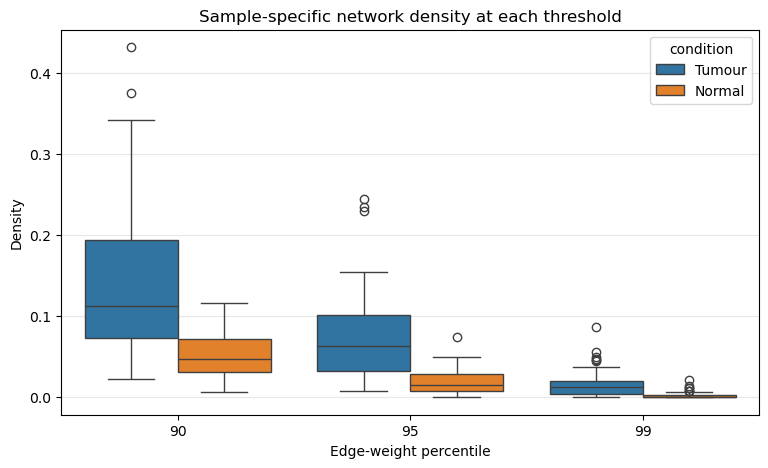

In [12]:
# per-sample density by threshold, split by group
plt.figure(figsize=(9, 5))
sns.boxplot(data=sample_density, x="Percentile", y="Density", hue="condition")
plt.title("Sample-specific network density at each threshold")
plt.xlabel("Edge-weight percentile")
plt.ylabel("Density")
plt.grid(axis="y", alpha=0.3)
plt.savefig("../results/sample_specific_density.png", dpi=300, bbox_inches="tight")
plt.show()

In [13]:
# spearman correlation between every pair of sample networks
network_samples = sample_weights.columns.tolist()
conditions = metadata.set_index("sample").loc[network_samples, "condition"]
labels = conditions.to_numpy()

network_similarity = sample_weights.corr(method="spearman")
similarity_array = network_similarity.to_numpy()
print(similarity_array.shape, "| groups:", dict(conditions.value_counts()))

(107, 107) | groups: {'Tumour': np.int64(58), 'Normal': np.int64(49)}


In [14]:
# within-group vs between-group similarity
def pair_values(sim, lab):
    """upper-triangle similarities split into TT, NN and TN pairs"""
    upper = np.triu(np.ones(sim.shape, dtype=bool), k=1)
    t, n = lab == "Tumour", lab == "Normal"
    tt = upper & np.outer(t, t)
    nn = upper & np.outer(n, n)
    tn = upper & (np.outer(t, n) | np.outer(n, t))
    return sim[tt], sim[nn], sim[tn]

def summarise(sim, lab):
    tt, nn, tn = pair_values(sim, lab)
    return pd.DataFrame({
        "Comparison": ["Tumour-Tumour", "Normal-Normal", "Tumour-Normal"],
        "Mean_Spearman_Correlation": [tt.mean(), nn.mean(), tn.mean()],
        "Number_of_Pairs": [len(tt), len(nn), len(tn)],
    })

comparison_df = summarise(similarity_array, labels)
comparison_df

,Comparison,Mean_Spearman_Correlation,Number_of_Pairs
0,Tumour-Tumour,0.307244,1653
1,Normal-Normal,0.561134,1176
2,Tumour-Normal,0.405371,2842


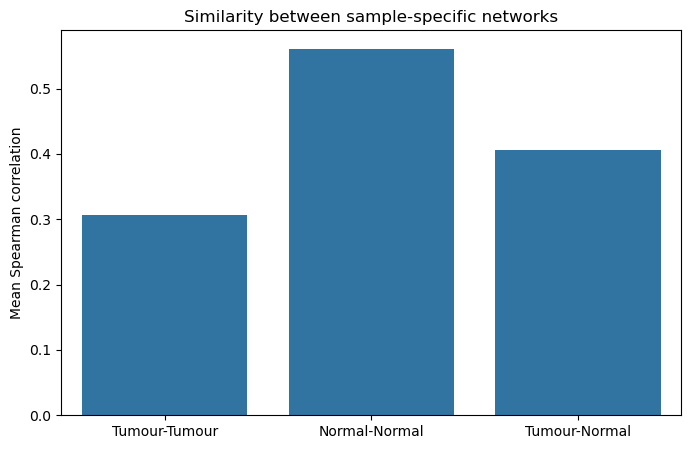

In [15]:
plt.figure(figsize=(8, 5))
sns.barplot(data=comparison_df, x="Comparison", y="Mean_Spearman_Correlation")
plt.title("Similarity between sample-specific networks")
plt.xlabel("")
plt.ylabel("Mean Spearman correlation")
plt.savefig("../results/network_group_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

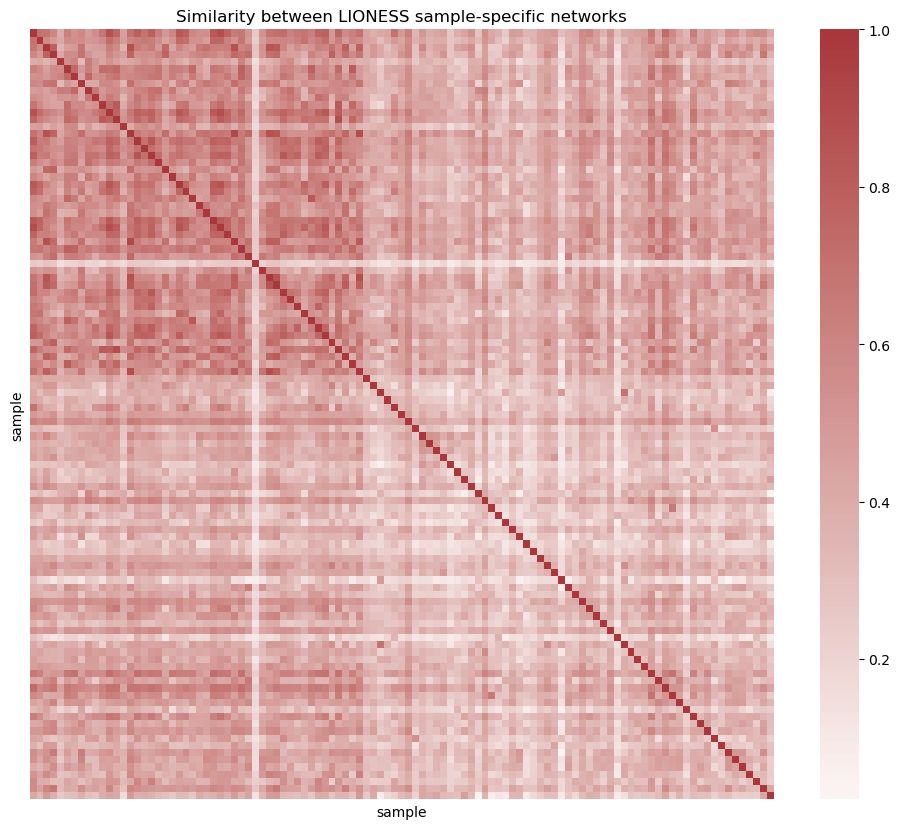

In [16]:
# similarity matrix with samples sorted by group
order = conditions.sort_values().index
plt.figure(figsize=(12, 10))
sns.heatmap(network_similarity.loc[order, order], cmap="vlag", center=0,
            xticklabels=False, yticklabels=False)
plt.title("Similarity between LIONESS sample-specific networks")
plt.savefig("../results/network_similarity_heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

In [17]:
# is the Normal-Normal vs Tumour-Tumour gap bigger than what shuffled labels give?
# (the 1,653 / 1,176 pairs are not independent, so no p-value from the pair counts)
def group_gap(sim, lab):
    tt, nn, _ = pair_values(sim, lab)
    return nn.mean() - tt.mean()

rng = np.random.default_rng(0)
obs = group_gap(similarity_array, labels)
null = np.array([group_gap(similarity_array, rng.permutation(labels)) for _ in range(5000)])
p_perm = (np.sum(null >= obs) + 1) / (len(null) + 1)

print(f"observed gap (NN - TT): {obs:.3f}")
print(f"permutation p-value (5000 shuffles): {p_perm:.4f}")

observed gap (NN - TT): 0.254
permutation p-value (5000 shuffles): 0.0002


In [18]:
# control: do plain expression profiles (same 100 probes) show the same pattern?
expr_sim = expression_filtered[network_samples].corr(method="spearman").to_numpy()
expression_comparison = summarise(expr_sim, labels)

print("expression gap (NN - TT):", round(group_gap(expr_sim, labels), 3))
expression_comparison

expression gap (NN - TT): 0.324


,Comparison,Mean_Spearman_Correlation,Number_of_Pairs
0,Tumour-Tumour,0.541672,1653
1,Normal-Normal,0.865680,1176
2,Tumour-Normal,0.332707,2842


In [19]:
# paired design: is a patient's tumour closer to their own normal than to other normals?
pair_info = metadata.set_index("sample").loc[network_samples]
tumour_ids = pair_info.index[pair_info["condition"] == "Tumour"]
normal_ids = pair_info.index[pair_info["condition"] == "Normal"]

own, other = [], []
for t in tumour_ids:
    patient = pair_info.loc[t, "patient"]
    for n in normal_ids:
        (own if pair_info.loc[n, "patient"] == patient else other).append(
            network_similarity.loc[t, n])

print(f"same-patient tumour-normal pairs: {len(own)}, mean = {np.mean(own):.3f}")
print(f"different-patient tumour-normal pairs: {len(other)}, mean = {np.mean(other):.3f}")

same-patient tumour-normal pairs: 33, mean = 0.366
different-patient tumour-normal pairs: 2809, mean = 0.406


In [20]:
# save tables
threshold_df.to_csv("../results/threshold_analysis.csv", index=False)
sample_density.to_csv("../results/sample_specific_density.csv", index=False)
network_similarity.to_csv("../results/network_similarity.csv")
comparison_df.to_csv("../results/network_group_comparison.csv", index=False)
expression_comparison.to_csv("../results/expression_group_comparison.csv", index=False)
metadata.to_csv("../results/sample_metadata.csv", index=False)

print(sorted(os.listdir("../results")))

['LIONESS_all_samples.csv', 'expression_group_comparison.csv', 'gene_set_sweep.csv', 'gene_set_sweep.png', 'network_group_comparison.csv', 'network_group_comparison.png', 'network_similarity.csv', 'network_similarity_heatmap.png', 'random_probe_repeats.csv', 'sample_metadata.csv', 'sample_specific_density.csv', 'sample_specific_density.png', 'threshold_analysis.csv']


In [21]:
# does the result hold for different gene sets? (top-variance sets of different sizes + random probes)
import contextlib

def run_sweep(gene_ids, label):
    expr = expression.loc[gene_ids]
    with contextlib.redirect_stdout(io.StringIO()):
        p = Panda(expr, None, None, keep_expression_matrix=True,
                  with_header=True, computing="cpu")
        l = Lioness(p, computing="cpu", ncores=2, output="network", save_single=False)
    res = l.export_lioness_results.copy()
    res = res[res["gene1"] != res["gene2"]]
    w = res.drop(columns=["gene1", "gene2"]).apply(pd.to_numeric, errors="coerce")

    lab = conditions.loc[w.columns].to_numpy()
    tt, nn, tn = pair_values(w.corr(method="spearman").to_numpy(), lab)
    ett, enn, etn = pair_values(expr[w.columns].corr(method="spearman").to_numpy(), lab)
    return {"Gene_set": label, "N_probes": len(gene_ids),
            "TT": tt.mean(), "NN": nn.mean(), "TN": tn.mean(),
            "Net_gap_NN_minus_TT": nn.mean() - tt.mean(),
            "Expr_gap_NN_minus_TT": enn.mean() - ett.mean(),
            "Net_TN_minus_TT": tn.mean() - tt.mean()}

ranked = gene_variance.sort_values(ascending=False).index
rng = np.random.default_rng(0)
sets = {f"top {k} variable": ranked[:k] for k in [50, 100, 200, 500]}
sets["random 100"] = rng.choice(expression.index, 100, replace=False)

sweep_df = pd.DataFrame([run_sweep(g, name) for name, g in sets.items()])
sweep_df.to_csv("../results/gene_set_sweep.csv", index=False)
sweep_df.round(3)

,Gene_set,N_probes,TT,NN,TN,Net_gap_NN_minus_TT,Expr_gap_NN_minus_TT,Net_TN_minus_TT
0,top 50 variable,50,0.348,0.513,0.421,0.164,0.302,0.073
1,top 100 variable,100,0.307,0.561,0.405,0.254,0.324,0.098
2,top 200 variable,200,0.323,0.597,0.426,0.275,0.235,0.103
3,top 500 variable,500,0.287,0.588,0.392,0.301,0.205,0.105
4,random 100,100,0.127,0.238,0.166,0.111,0.027,0.039


,Net_gap_NN_minus_TT,Expr_gap_NN_minus_TT,Net_TN_minus_TT
mean,0.110,0.027,0.040
std,0.011,0.008,0.003
min,0.093,0.016,0.034
max,0.127,0.038,0.044


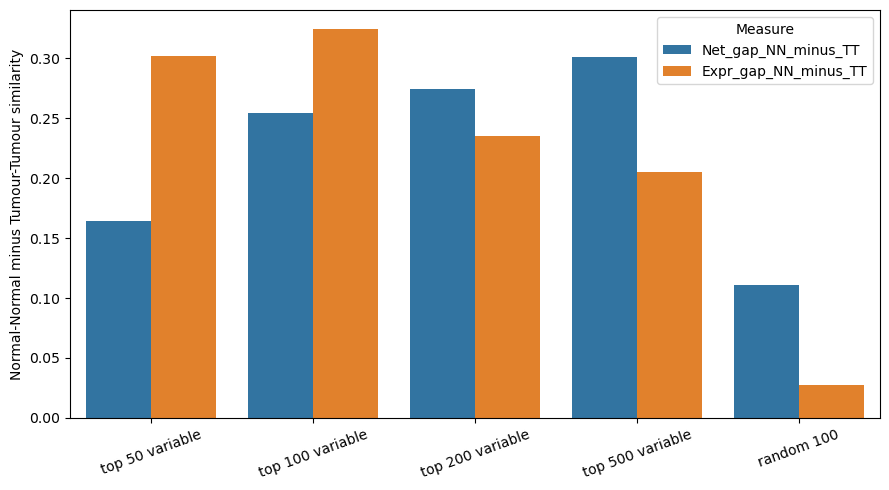

In [22]:
# repeat the random-probe control with 10 different seeds
rows = []
for seed in range(10):
    g = np.random.default_rng(seed).choice(expression.index, 100, replace=False)
    rows.append(run_sweep(g, f"random 100 (seed {seed})"))
random_df = pd.DataFrame(rows)
random_df.to_csv("../results/random_probe_repeats.csv", index=False)

cols = ["Net_gap_NN_minus_TT", "Expr_gap_NN_minus_TT", "Net_TN_minus_TT"]
display(random_df[cols].describe().loc[["mean", "std", "min", "max"]].round(3))

# figure: network gap vs expression gap for each gene set
plot_df = sweep_df.melt(id_vars="Gene_set",
                        value_vars=["Net_gap_NN_minus_TT", "Expr_gap_NN_minus_TT"],
                        var_name="Measure", value_name="Gap")
plt.figure(figsize=(9, 5))
sns.barplot(data=plot_df, x="Gene_set", y="Gap", hue="Measure")
plt.xticks(rotation=20)
plt.ylabel("Normal-Normal minus Tumour-Tumour similarity")
plt.xlabel("")
plt.tight_layout()
plt.savefig("../results/gene_set_sweep.png", dpi=300, bbox_inches="tight")
plt.show()

In [23]:
# do LIONESS edges behave like products of z-scores?
from scipy.stats import spearmanr

Z = expression_filtered[network_samples]
Z = Z.sub(Z.mean(axis=1), axis=0).div(Z.std(axis=1), axis=0)   # probes x samples

g1 = filtered_results["gene1"].to_numpy()
g2 = filtered_results["gene2"].to_numpy()
prod = Z.loc[g1].to_numpy() * Z.loc[g2].to_numpy()               # 9900 edges x 107 samples

# 1) per-sample agreement between LIONESS edges and z-score products
r = [spearmanr(sample_weights[s], prod[:, k])[0] for k, s in enumerate(network_samples)]
print(f"LIONESS vs z-product, per-sample Spearman: median {np.median(r):.2f}, "
      f"range {np.min(r):.2f} to {np.max(r):.2f}")

# 2) does the z-product 'network' reproduce the group pattern?
prod_sim = pd.DataFrame(prod, columns=network_samples).corr(method="spearman").to_numpy()
print(summarise(prod_sim, labels).round(3))
print("gap NN-TT:", round(group_gap(prod_sim, labels), 3))

In [23]:
# do LIONESS edges behave like products of z-scores?
from scipy.stats import spearmanr

Z = expression_filtered[network_samples]
Z = Z.sub(Z.mean(axis=1), axis=0).div(Z.std(axis=1), axis=0)   # probes x samples

g1 = filtered_results["gene1"].to_numpy()
g2 = filtered_results["gene2"].to_numpy()
prod = Z.loc[g1].to_numpy() * Z.loc[g2].to_numpy()               # 9900 edges x 107 samples

# 1) per-sample agreement between LIONESS edges and z-score products
r = [spearmanr(sample_weights[s], prod[:, k])[0] for k, s in enumerate(network_samples)]
print(f"LIONESS vs z-product, per-sample Spearman: median {np.median(r):.2f}, "
      f"range {np.min(r):.2f} to {np.max(r):.2f}")

# 2) does the z-product 'network' reproduce the group pattern?
prod_sim = pd.DataFrame(prod, columns=network_samples).corr(method="spearman").to_numpy()
print(summarise(prod_sim, labels).round(3))
print("gap NN-TT:", round(group_gap(prod_sim, labels), 3))

In [24]:
# side-by-side summary of all three measures (saves a table for the README / slides)
three = pd.DataFrame({
    "LIONESS network": comparison_df.set_index("Comparison")["Mean_Spearman_Correlation"],
    "z-score product": summarise(prod_sim, labels).set_index("Comparison")["Mean_Spearman_Correlation"],
    "Expression profile": expression_comparison.set_index("Comparison")["Mean_Spearman_Correlation"],
}).round(3)
three.loc["NN - TT"] = three.loc["Normal-Normal"] - three.loc["Tumour-Tumour"]
three.loc["TN - TT"] = three.loc["Tumour-Normal"] - three.loc["Tumour-Normal"] * 0 - three.loc["Tumour-Tumour"]
three.to_csv("../results/three_way_comparison.csv")
three

# which samples agree least with the z-score product? (r ranges down to 0.53)
low = pd.Series(r, index=network_samples).sort_values().head(8)
pd.concat([low.rename("r"), conditions.loc[low.index].rename("group")], axis=1)

,r,group
GSM254729,0.528934,Tumour
GSM254637,0.651280,Tumour
GSM254625,0.655035,Tumour
GSM254656,0.676098,Tumour
GSM254726,0.678029,Tumour
GSM254694,0.679259,Tumour
GSM254648,0.747160,Tumour
GSM254632,0.747754,Normal


In [25]:
# are low-agreement samples the more extreme ones?
extreme = Z.abs().mean(axis=0)            # mean |z| across the 100 probes, per sample
chk = pd.DataFrame({"r": r, "mean_abs_z": extreme.loc[network_samples].to_numpy(),
                    "group": labels}, index=network_samples)

print("Spearman(r, mean |z|):", round(spearmanr(chk["r"], chk["mean_abs_z"])[0], 2))
print(chk.groupby("group")[["r", "mean_abs_z"]].median().round(3))

Spearman(r, mean |z|): 0.58
            r  mean_abs_z
group                    
Normal  0.975       0.863
Tumour  0.932       0.870
